# 1. Imports, Data Collection & Cleaning

## 1.1 Library Imports  

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm

## 1.2 Data Collection

In [2]:
df = pd.read_csv("/Users/kovalskyy/Downloads/XAU End of Week Retracement/dataset/GC Daily OHLC Data_clean.csv")

df.head()

,datetime,symbol,open,high,low,close,volume
0,2010-01-03 23:00:00,COMEX:GC1!,1099.0,1124.6,1093.8,1118.3,155479
1,2010-01-04 23:00:00,COMEX:GC1!,1122.0,1129.6,1115.5,1118.7,156414
2,2010-01-05 23:00:00,COMEX:GC1!,1118.5,1141.0,1116.8,1136.5,176903
3,2010-01-06 23:00:00,COMEX:GC1!,1139.0,1139.5,1128.7,1133.7,121150
4,2010-01-07 23:00:00,COMEX:GC1!,1131.5,1140.0,1119.5,1138.9,212621


## 1.3 Data Cleaning

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3975 entries, 0 to 3974
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   datetime  3975 non-null   str    
 1   symbol    3975 non-null   str    
 2   open      3975 non-null   float64
 3   high      3975 non-null   float64
 4   low       3975 non-null   float64
 5   close     3975 non-null   float64
 6   volume    3975 non-null   int64  
dtypes: float64(4), int64(1), str(2)
memory usage: 217.5 KB


In [4]:
# Removing unnecessary columns
df = df[["datetime", "close", "high", "low", "open"]]

# Setting new index and correcting data types
df = df.set_index("datetime", drop=True)
df.index = pd.to_datetime(df.index)

# Daily timestamps mark the previous evening's session opening.
# Move every session to its trading date: Sunday -> Monday, Thursday -> Friday.
# Moving only Sundays would duplicate Monday dates and leave Fridays missing.
df.index = (df.index + pd.Timedelta(days=1)).normalize()

df.head()

,close,high,low,open
datetime,,,,
2010-01-04,1118.3,1124.6,1093.8,1099.0
2010-01-05,1118.7,1129.6,1115.5,1122.0
2010-01-06,1136.5,1141.0,1116.8,1118.5
2010-01-07,1133.7,1139.5,1128.7,1139.0
2010-01-08,1138.9,1140.0,1119.5,1131.5


In [5]:
# Cheking missing values
df.isna().sum()

close    0
high     0
low      0
open     0
dtype: int64

In [6]:
# Cheking duplicates
print(f"Number of duplicated rows: {df.duplicated(keep=False).sum()}")

df[df.duplicated(keep=False)].head(10)

Number of duplicated rows: 0


,close,high,low,open
datetime,,,,


In [7]:
# Cheking duplicated dates
print(f"Number of duplicated dates: {df.index.duplicated().sum()}")

Number of duplicated dates: 0


In [8]:
# Cheking if removing duplicated rows will affect our features
df["weekday"] = df.index.day_name()
df[['year_number', 'week_number', 'day_number']] = df.index.isocalendar()[['year', 'week', 'day']]

df = df[[
    'year_number',
    'week_number',
    'day_number',
    'weekday',
    'close',
    'high',
    'low',
    'open',
]]

In [9]:
# Cheking trading days on weekends are present
mask = df["weekday"].isin(["Saturday", "Sunday"])

print(f"Number of trading days on the weekend: {df.loc[mask, 'weekday'].count()}\n")

Number of trading days on the weekend: 0



## 1.4 Checking suspicious OHLC values

In [10]:
# Check all candles; show suspicious rows without removing them.
ohlc = df[["open", "high", "low", "close"]].apply(pd.to_numeric, errors="coerce")
finite = pd.Series(np.isfinite(ohlc.to_numpy(dtype=float)).all(axis=1), index=df.index)
valid_prices = finite & ohlc.gt(0).all(axis=1)

checks = pd.DataFrame({
    "missing_or_non_numeric": ohlc.isna().any(axis=1),
    "infinite_price": ohlc.isin([np.inf, -np.inf]).any(axis=1),
    "non_positive_price": ohlc.le(0).any(axis=1),
    "low_above_high": finite & ohlc["low"].gt(ohlc["high"]),
    "open_outside_range": finite & (ohlc["open"].lt(ohlc["low"]) | ohlc["open"].gt(ohlc["high"])),
    "close_outside_range": finite & (ohlc["close"].lt(ohlc["low"]) | ohlc["close"].gt(ohlc["high"])),
}, index=df.index)
invalid = checks.any(axis=1)

# Review flags: open == close (doji) is not automatically an error.
checks["flat_candle"] = valid_prices & ~invalid & ohlc.nunique(axis=1).eq(1)
checks["doji"] = valid_prices & ~invalid & ohlc["open"].eq(ohlc["close"]) & ~checks["flat_candle"]
checks["repeated_ohlc"] = valid_prices & ohlc.duplicated(keep=False)

mask = checks.any(axis=1)
suspicious = df.loc[mask, ["weekday", "open", "high", "low", "close"]].copy()
suspicious["reason"] = [
    "; ".join(row.index[row]) for _, row in checks.loc[mask].iterrows()
]

print(f"Invalid OHLC candles: {invalid.sum()}")
print(f"Suspicious candles for review: {len(suspicious)}\n")
print(suspicious.to_string())

Invalid OHLC candles: 0
Suspicious candles for review: 11

              weekday    open    high     low   close       reason
datetime                                                          
2010-07-21  Wednesday  1191.8  1198.0  1183.0  1191.8         doji
2011-07-28   Thursday  1616.2  1622.8  1605.0  1616.2         doji
2013-03-06  Wednesday  1574.9  1584.3  1566.4  1574.9         doji
2013-08-30     Friday  1396.1  1396.1  1396.1  1396.1  flat_candle
2013-09-23     Monday  1327.0  1332.0  1313.4  1327.0         doji
2015-07-03     Friday  1173.2  1174.4  1161.9  1173.2         doji
2017-07-19  Wednesday  1242.0  1243.5  1235.1  1242.0         doji
2019-08-02     Friday  1457.5  1461.9  1442.5  1457.5         doji
2019-10-22    Tuesday  1487.5  1492.1  1484.0  1487.5         doji
2019-12-17    Tuesday  1480.6  1484.9  1478.4  1480.6         doji
2020-09-15    Tuesday  1966.2  1982.4  1955.6  1966.2         doji


# 2. Feature Engineering

Research question: after a directional move through Thursday, does Friday reverse
that direction more often than it continues it? The main specification includes
the weekend gap; the alternative excludes it as a robustness check.

This section prepares one row per calendar week for review. It does not estimate probabilities.
The flat candle is retained.

## 2.1 Feature Definitions

| Feature | Definition |
|---|---|
| `move_4d_gap` | Current Thursday close − previous calendar week's Friday close |
| `move_4d_no_gap` | Current Thursday close − current Monday open |
| `move_4d_gap_pct` | `100 × move_4d_gap / previous Friday close` |
| `move_4d_no_gap_pct` | `100 × move_4d_no_gap / Monday open` |
| `friday_move` | Friday close − Friday open |
| `friday_move_pct` | `100 × friday_move / Friday open` |
| `friday_outcome_gap` | Friday direction relative to `move_4d_gap` |
| `friday_outcome_no_gap` | Friday direction relative to `move_4d_no_gap` |

Friday's move is measured **open to close** in both specifications, so the
Thursday-to-Friday opening gap does not determine the Friday outcome.
`reversal` means strictly opposite signs; `continuation` means strictly equal nonzero signs.
Here reversal means an opposite-direction Friday, not necessarily a full recovery of the four-day move.
A zero four-day move is `no_prior_direction`; a zero Friday move is `neutral_friday`.
If both are zero, use `no_prior_direction`. Missing inputs are `unavailable`.

For the later short-narrative/Friday-long test, select negative `move_4d_gap`;
a strictly positive `friday_move` then counts as reversal.
All endpoint prices are on the trading dates established in section 1.3.

## 2.2 Weekly Price Endpoints

The main specification requires the **immediately previous calendar Friday**,
current Monday, Thursday and Friday. The robustness specification requires only
current Monday, Thursday and Friday. Tuesday and Wednesday are not required.
Do not substitute an older Friday if the previous calendar Friday is missing.
Keep incomplete weeks visible with eligibility flags.

In [11]:
# Work on a separate weekly table; keep the daily df unchanged.
daily = df[["open", "close"]].sort_index().copy()
if daily.index.has_duplicates:
    raise ValueError("Duplicate trading dates: resolve them before building weekly features.")

daily["week_start"] = daily.index - pd.to_timedelta(daily.index.dayofweek, unit="D")
daily["day_number"] = daily.index.dayofweek + 1
week_starts = pd.date_range(daily["week_start"].min(), daily["week_start"].max(), freq="W-MON")
weekly_features = pd.DataFrame(index=week_starts)
weekly_features.index.name = "week_start"

weekly_open = daily.pivot(index="week_start", columns="day_number", values="open")
weekly_close = daily.pivot(index="week_start", columns="day_number", values="close")
weekly_features["monday_open"] = weekly_open.reindex(index=week_starts, columns=[1])[1]
weekly_features["thursday_close"] = weekly_close.reindex(index=week_starts, columns=[4])[4]
weekly_features["friday_open"] = weekly_open.reindex(index=week_starts, columns=[5])[5]
weekly_features["friday_close"] = weekly_close.reindex(index=week_starts, columns=[5])[5]

previous_friday_dates = week_starts - pd.Timedelta(days=3)
weekly_features["previous_friday_close"] = daily["close"].reindex(previous_friday_dates).to_numpy()
weekly_features.head()

,monday_open,thursday_close,friday_open,friday_close,previous_friday_close
week_start,,,,,
2010-01-04,1099.0,1133.7,1131.5,1138.9,NaN
2010-01-11,1139.0,1143.0,1142.0,1130.5,1138.9
2010-01-18,1130.7,1103.2,1095.4,1089.7,1130.5
2010-01-25,1093.5,1084.8,1087.0,1083.8,1089.7
2010-02-01,1081.9,1063.0,1065.7,1052.8,1083.8


## 2.3 Four-Day Moves and Friday Move

In [12]:
# Keep signed moves in price units and percentages.
weekly_features["move_4d_gap"] = (
    weekly_features["thursday_close"] - weekly_features["previous_friday_close"]
).where(weekly_features["monday_open"].notna())
weekly_features["move_4d_no_gap"] = (
    weekly_features["thursday_close"] - weekly_features["monday_open"]
)
weekly_features["friday_move"] = weekly_features["friday_close"] - weekly_features["friday_open"]

weekly_features["move_4d_gap_pct"] = 100 * weekly_features["move_4d_gap"] / weekly_features["previous_friday_close"]
weekly_features["move_4d_no_gap_pct"] = 100 * weekly_features["move_4d_no_gap"] / weekly_features["monday_open"]
weekly_features["friday_move_pct"] = 100 * weekly_features["friday_move"] / weekly_features["friday_open"]

weekly_features[["move_4d_gap", "move_4d_gap_pct", "move_4d_no_gap", "move_4d_no_gap_pct",
                 "friday_move", "friday_move_pct"]].head()

,move_4d_gap,move_4d_gap_pct,move_4d_no_gap,move_4d_no_gap_pct,friday_move,friday_move_pct
week_start,,,,,,
2010-01-04,NaN,NaN,34.7,3.157416,7.4,0.653999
2010-01-11,4.1,0.359996,4.0,0.351185,-11.5,-1.007005
2010-01-18,-27.3,-2.414861,-27.5,-2.432122,-5.7,-0.520358
2010-01-25,-4.9,-0.449665,-8.7,-0.795610,-3.2,-0.294388
2010-02-01,-20.8,-1.919173,-18.9,-1.746927,-12.9,-1.210472


## 2.4 Strict Reversal / Continuation Labels

In [13]:
def classify_friday(prior_move, friday_move):
    available = prior_move.notna() & friday_move.notna()
    opposite = ((prior_move < 0) & (friday_move > 0)) | ((prior_move > 0) & (friday_move < 0))
    same = ((prior_move < 0) & (friday_move < 0)) | ((prior_move > 0) & (friday_move > 0))
    return pd.Series(np.select(
        [~available, prior_move.eq(0), friday_move.eq(0), opposite, same],
        ["unavailable", "no_prior_direction", "neutral_friday", "reversal", "continuation"],
        default="unavailable",
    ), index=prior_move.index, dtype="string")


# Eligibility follows the required endpoints, not the number of weekdays present.
required_endpoints = {
    "gap": ["previous_friday_close", "monday_open", "thursday_close", "friday_open", "friday_close"],
    "no_gap": ["monday_open", "thursday_close", "friday_open", "friday_close"],
}

for specification, columns in required_endpoints.items():
    eligible = weekly_features[columns].notna().all(axis=1)
    weekly_features[f"eligible_{specification}"] = eligible
    prior_move = weekly_features[f"move_4d_{specification}"].where(eligible)
    weekly_features[f"friday_outcome_{specification}"] = classify_friday(prior_move, weekly_features["friday_move"])
    weekly_features[f"directional_{specification}"] = (
        weekly_features[f"friday_outcome_{specification}"].isin(["reversal", "continuation"])
    )

## 2.5 Feature Preview

`eligible_*` identifies weeks with the required inputs, including neutral outcomes.
`directional_*` identifies weeks with a strict reversal/continuation label.
Both flags remain separate so neutral Fridays are visible when choosing the later research denominator.

In [14]:
print(f"Calendar weeks in dataset: {len(weekly_features)}")
print(f"Weeks with main-specification inputs: {weekly_features['eligible_gap'].sum()}")
print(f"Weeks with robustness-specification inputs: {weekly_features['eligible_no_gap'].sum()}")

preview_columns = ["previous_friday_close", "monday_open", "thursday_close", "friday_open", "friday_close",
                   "move_4d_gap", "move_4d_no_gap", "friday_move",
                   "friday_outcome_gap", "friday_outcome_no_gap", "eligible_gap", "eligible_no_gap"]
display(weekly_features[preview_columns].head(10))

# Keep the week containing the flat Friday visible for review.
display(weekly_features.loc[[pd.Timestamp("2013-08-26")], preview_columns])

Calendar weeks in dataset: 824
Weeks with main-specification inputs: 723
Weeks with robustness-specification inputs: 763


,previous_friday_close,monday_open,thursday_close,friday_open,friday_close,move_4d_gap,move_4d_no_gap,friday_move,friday_outcome_gap,friday_outcome_no_gap,eligible_gap,eligible_no_gap
week_start,,,,,,,,,,,,
2010-01-04,NaN,1099.0,1133.7,1131.5,1138.9,NaN,34.7,7.4,unavailable,continuation,False,True
2010-01-11,1138.9,1139.0,1143.0,1142.0,1130.5,4.1,4.0,-11.5,reversal,reversal,True,True
2010-01-18,1130.5,1130.7,1103.2,1095.4,1089.7,-27.3,-27.5,-5.7,continuation,continuation,True,True
2010-01-25,1089.7,1093.5,1084.8,1087.0,1083.8,-4.9,-8.7,-3.2,continuation,continuation,True,True
2010-02-01,1083.8,1081.9,1063.0,1065.7,1052.8,-20.8,-18.9,-12.9,continuation,continuation,True,True
2010-02-08,1052.8,1068.3,1094.7,1094.6,1090.0,41.9,26.4,-4.6,reversal,reversal,True,True
2010-02-15,1090.0,1093.7,1118.7,1108.4,1122.1,28.7,25.0,13.7,continuation,continuation,True,True
2010-02-22,1122.1,1122.1,1108.5,1108.0,1118.9,-13.6,-13.6,10.9,reversal,reversal,True,True
2010-03-01,1118.9,1119.0,1133.1,1132.9,1135.2,14.2,14.1,2.3,continuation,continuation,True,True


,previous_friday_close,monday_open,thursday_close,friday_open,friday_close,move_4d_gap,move_4d_no_gap,friday_move,friday_outcome_gap,friday_outcome_no_gap,eligible_gap,eligible_no_gap
week_start,,,,,,,,,,,,
2013-08-26,1395.8,1399.0,1412.9,1396.1,1396.1,17.1,13.9,0.0,neutral_friday,neutral_friday,True,True


# 3. Exploratory Data Analysis (EDA)

Compare observed Friday reversal/continuation frequencies for the main test
(weekend gap included) and the robustness check (weekend gap excluded).
No hypothesis tests or claims of statistical significance are made here.

## 3.1 Sample Sizes and Neutral Outcomes

The frequency charts use only weeks classified as `reversal` or `continuation`.
Their denominator is shown as **N**. Neutral Fridays, weeks without a prior direction
and unavailable weeks are counted separately below; they remain in `weekly_features`.

In [15]:
specification_names = {"gap": "Main: with gap", "no_gap": "Robustness: no gap"}
outcome_order = ["reversal", "continuation"]
status_order = outcome_order + ["neutral_friday", "no_prior_direction", "unavailable"]

eda_sample_sizes = pd.DataFrame({
    name: weekly_features[f"friday_outcome_{specification}"].value_counts().reindex(status_order, fill_value=0)
    for specification, name in specification_names.items()
}).T
eda_sample_sizes["directional_N"] = eda_sample_sizes[outcome_order].sum(axis=1)
eda_sample_sizes["eligible_N"] = eda_sample_sizes[status_order[:-1]].sum(axis=1)
display(eda_sample_sizes)

,reversal,continuation,neutral_friday,no_prior_direction,unavailable,directional_N,eligible_N
Main: with gap,362,358,3,0,101,720,723
Robustness: no gap,386,374,3,0,61,760,763


## 3.2 Overall Reversal / Continuation Frequencies

Each panel shows percentages within its own directional sample, with the count
on each bar. The specifications have different sample sizes; this is a descriptive
comparison of their respective eligible samples.

,specification,outcome,count,directional_N,frequency_pct
0,Main: with gap,reversal,362,720,50.28
1,Main: with gap,continuation,358,720,49.72
2,Robustness: no gap,reversal,386,760,50.79
3,Robustness: no gap,continuation,374,760,49.21


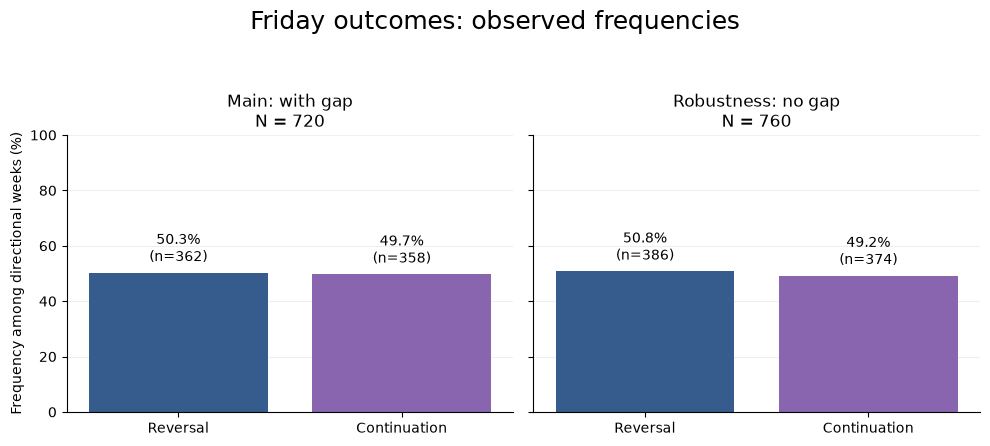

In [16]:
frequency_rows = []
for specification, name in specification_names.items():
    counts = eda_sample_sizes.loc[name, outcome_order]
    denominator = int(counts.sum())
    for outcome in outcome_order:
        count = int(counts[outcome])
        frequency_rows.append({
            "specification": name, "outcome": outcome, "count": count,
            "directional_N": denominator,
            "frequency_pct": 100 * count / denominator if denominator else np.nan,
        })
eda_frequencies = pd.DataFrame(frequency_rows)
display(eda_frequencies.round({"frequency_pct": 2}))

# Seaborn draws the bars; matplotlib's ax controls each subplot.
outcome_colors = {"reversal": "#355C8C", "continuation": "#8965B0"}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)

for ax, name in zip(axes, specification_names.values()):
    panel = eda_frequencies[eda_frequencies["specification"] == name]

    sns.barplot(data=panel, x="outcome", y="frequency_pct",
                order=outcome_order, color="#355C8C", errorbar=None, ax=ax)

    for bar, color in zip(ax.patches, outcome_colors.values()):
        bar.set_facecolor(color)

    labels = [f"{percent:.1f}%\n(n={count})"
              for percent, count in zip(panel["frequency_pct"], panel["count"])]
    ax.bar_label(ax.containers[0], labels=labels, padding=5)

    ax.set_title(f"{name}\nN = {int(panel['directional_N'].iloc[0])}", fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("Frequency among directional weeks (%)")
    ax.set_ylim(0, 100)
    ax.set_xticks([0, 1], labels=["Reversal", "Continuation"])
    ax.set_yticks([0, 20, 40, 60, 80, 100])
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    sns.despine(ax=ax)

axes[1].set_ylabel("")
fig.suptitle("Friday outcomes: observed frequencies", fontsize=18)
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

## 3.3 Frequencies by Prior Direction

Separate short and long prior narratives so the aggregate does not hide differences.
After a **short** narrative, reversal means a positive Friday open-to-close move;
after a **long** narrative, reversal means a negative Friday move.
N is the number of directional outcomes within each narrative and specification.

,specification,prior_narrative,outcome,count,directional_N,frequency_pct
0,Main: with gap,Short,reversal,188,337,55.79
1,Main: with gap,Short,continuation,149,337,44.21
2,Main: with gap,Long,reversal,174,383,45.43
3,Main: with gap,Long,continuation,209,383,54.57
4,Robustness: no gap,Short,reversal,205,365,56.16
5,Robustness: no gap,Short,continuation,160,365,43.84
6,Robustness: no gap,Long,reversal,181,395,45.82
7,Robustness: no gap,Long,continuation,214,395,54.18


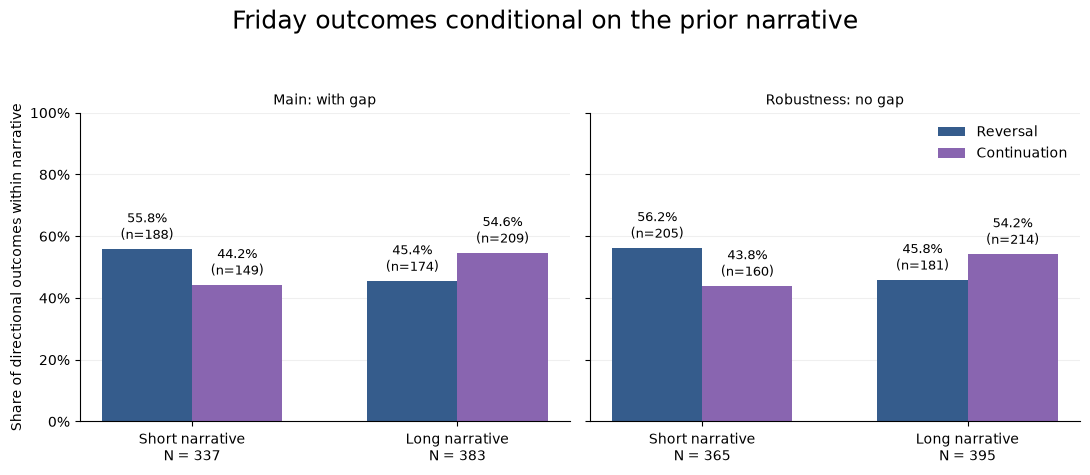

In [17]:
direction_rows = []
for specification, name in specification_names.items():
    prior = weekly_features[f"move_4d_{specification}"]
    outcome = weekly_features[f"friday_outcome_{specification}"]
    for narrative, prior_mask in [("Short", prior.lt(0)), ("Long", prior.gt(0))]:
        counts = outcome.loc[prior_mask & weekly_features[f"directional_{specification}"]].value_counts()
        denominator = int(counts.sum())
        for label in outcome_order:
            count = int(counts.get(label, 0))
            direction_rows.append({
                "specification": name, "prior_narrative": narrative, "outcome": label,
                "count": count, "directional_N": denominator,
                "frequency_pct": 100 * count / denominator if denominator else np.nan,
            })
eda_by_direction = pd.DataFrame(direction_rows)
display(eda_by_direction.round({"frequency_pct": 2}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, name in zip(axes, specification_names.values()):
    panel = eda_by_direction.loc[eda_by_direction["specification"].eq(name)]
    positions = np.arange(2)
    width = 0.34
    for offset, label in [(-width / 2, "reversal"), (width / 2, "continuation")]:
        values = panel.loc[panel["outcome"].eq(label)].set_index("prior_narrative").reindex(["Short", "Long"])
        bars = ax.bar(positions + offset, values["frequency_pct"], width=width,
                      label=label.title(), color=outcome_colors[label])
        for bar, row in zip(bars, values.itertuples()):
            if pd.notna(row.frequency_pct):
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2,
                        f"{row.frequency_pct:.1f}%\n(n={row.count})", ha="center", va="bottom", fontsize=9)
    denominators = panel.groupby("prior_narrative")["directional_N"].first()
    ax.set_xticks(positions, labels=[f"{narrative} narrative\nN = {denominators[narrative]}" for narrative in ["Short", "Long"]])
    ax.set_title(name, fontsize=10)
    ax.set_ylim(0, 100)
    ax.set_yticks(range(0, 101, 20), labels=[f"{value}%" for value in range(0, 101, 20)])
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Share of directional outcomes within narrative")
axes[1].legend(loc="upper right", frameon=False)
fig.suptitle("Friday outcomes conditional on the prior narrative", fontsize=18)

fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

## 3.4 Four-Day Move vs Friday Move

Each point is one week: X is the four-day move (%), Y is Friday's open-to-close move (%).
Opposite signs (upper-left / lower-right) indicate reversal; equal nonzero signs
(upper-right / lower-left) indicate continuation. Points on either zero line are neutral.
Use all eligible weeks, including neutral Fridays, with shared axis scales and no outlier filtering.
The four-day move measures net direction and magnitude, not intraperiod volatility.

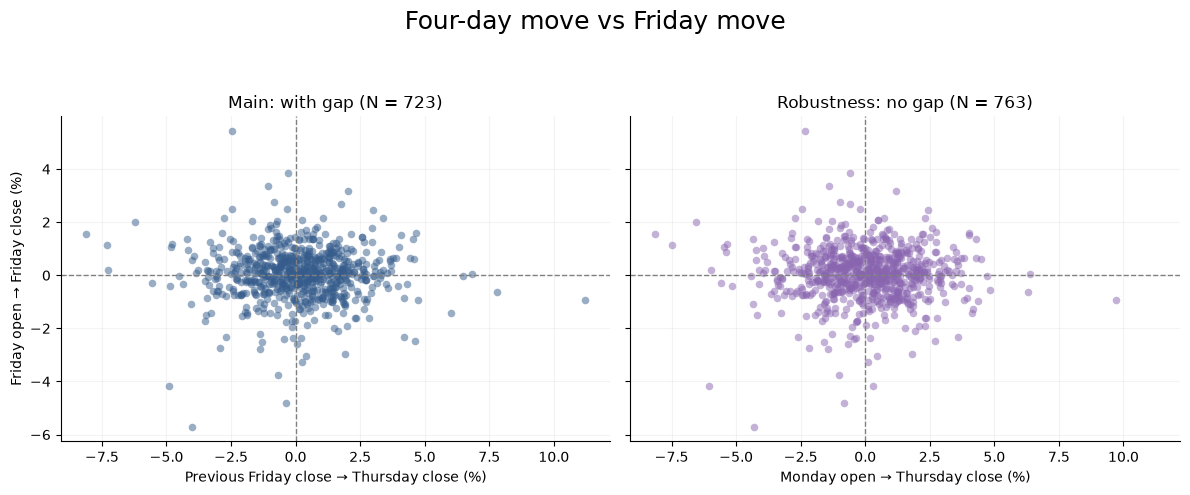

In [18]:
# Select weeks with the required prices for each specification.
main_data = weekly_features.loc[weekly_features["eligible_gap"]]
robustness_data = weekly_features.loc[weekly_features["eligible_no_gap"]]

# Shared axes make the two plots directly comparable.
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

ax = axes[0]
sns.scatterplot(data=main_data, x="move_4d_gap_pct", y="friday_move_pct",
                color="#355C8C", alpha=0.5, s=30, linewidth=0, ax=ax)
ax.set_title(f"Main: with gap (N = {len(main_data)})", fontsize=12)
ax.set_xlabel("Previous Friday close → Thursday close (%)")
ax.set_ylabel("Friday open → Friday close (%)")

ax = axes[1]
sns.scatterplot(data=robustness_data, x="move_4d_no_gap_pct", y="friday_move_pct",
                color="#8965B0", alpha=0.5, s=30, linewidth=0, ax=ax)
ax.set_title(f"Robustness: no gap (N = {len(robustness_data)})", fontsize=12)
ax.set_xlabel("Monday open → Thursday close (%)")
ax.set_ylabel("")

# Zero lines separate reversal and continuation quadrants.
for ax in axes:
    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_axisbelow(True)
    ax.grid(alpha=0.15)
    sns.despine(ax=ax)

fig.suptitle("Four-day move vs Friday move", fontsize=18)
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

# 4. Statistical Significance

Estimate the probability of Friday reversal **after a short four-day narrative**,
then test whether it exceeds 50%. In this group, reversal is a strictly positive
Friday open-to-close move; continuation is a strictly negative move.

Use the same denominator as EDA: reversal + continuation weeks. Neutral Fridays
remain in the weekly data but are excluded from this conditional probability.
Thus this estimates `P(Friday up | short narrative, non-neutral Friday, eligible week)`.

The binomial model assumes independent weeks with a constant success probability.
Results are exploratory because these observations were already reviewed in EDA.
The robustness sample overlaps the main sample, so it is not an independent replication.
These calculations do not establish that the narrative improves prediction over the
general Friday upward tendency; that is the later permutation-test question.

## 4.1 Short-Narrative Samples

Count reversal and continuation separately for the main specification and robustness,
and show how many neutral Fridays are excluded.

In [19]:
test_specifications = {"gap": "Main: with gap", "no_gap": "Robustness: no gap"}
sample_rows = []

for specification, name in test_specifications.items():
    short_mask = (
        weekly_features[f"eligible_{specification}"]
        & (weekly_features[f"move_4d_{specification}"] < 0)
    )
    outcomes = weekly_features.loc[short_mask, f"friday_outcome_{specification}"]
    reversals = int((outcomes == "reversal").sum())
    continuations = int((outcomes == "continuation").sum())

    sample_rows.append({
        "specification": name,
        "reversals": reversals,
        "continuations": continuations,
        "directional_N": reversals + continuations,
        "neutral_fridays": int((outcomes == "neutral_friday").sum()),
    })

short_samples = pd.DataFrame(sample_rows).set_index("specification")
display(short_samples)

,reversals,continuations,directional_N,neutral_fridays
specification,,,,
Main: with gap,188,149,337,1
Robustness: no gap,205,160,365,1


## 4.2 Reversal Confidence Intervals: Short vs Long Narrative

Use two-sided exact 95% binomial intervals for both narrative directions.
After a short narrative, reversal means Friday up; after a long narrative,
reversal means Friday down. Neutral Fridays are excluded from both denominators.
The assumptions and exploratory status stated above apply here as well.

In [20]:
from scipy.stats import binomtest

narrative_rows = []

for specification, name in test_specifications.items():
    prior_move = weekly_features[f"move_4d_{specification}"]
    for narrative, direction_mask in [("Short", prior_move < 0), ("Long", prior_move > 0)]:
        mask = weekly_features[f"eligible_{specification}"] & direction_mask
        outcomes = weekly_features.loc[mask, f"friday_outcome_{specification}"]
        k = int((outcomes == "reversal").sum())
        continuations = int((outcomes == "continuation").sum())
        n = k + continuations
        if n == 0:
            raise ValueError(f"No directional weeks for {name}, {narrative}.")

        interval = binomtest(k=k, n=n, alternative="two-sided").proportion_ci(
            confidence_level=0.95, method="exact"
        )
        narrative_rows.append({
            "specification": name, "narrative": narrative,
            "reversals": k, "continuations": continuations, "directional_N": n,
            "neutral_fridays": int((outcomes == "neutral_friday").sum()),
            "reversal_pct": 100 * k / n,
            "ci_95_low_pct": 100 * interval.low,
            "ci_95_high_pct": 100 * interval.high,
        })

narrative_intervals = pd.DataFrame(narrative_rows)
display(narrative_intervals.round(2))

,specification,narrative,reversals,continuations,directional_N,neutral_fridays,reversal_pct,ci_95_low_pct,ci_95_high_pct
0,Main: with gap,Short,188,149,337,1,55.79,50.30,61.17
1,Main: with gap,Long,174,209,383,2,45.43,40.37,50.57
2,Robustness: no gap,Short,205,160,365,1,56.16,50.90,61.32
3,Robustness: no gap,Long,181,214,395,2,45.82,40.83,50.88


## 4.3 One-Sided Binomial Test Against 50%

- **H0:** reversal probability is at most 50%.
- **H1:** reversal probability is greater than 50%.
- Significance level: `alpha = 0.05`.

Calculate the exact upper-tail p-value at the null boundary `p = 0.5`.

In [21]:
alpha = 0.05
test_rows = []

for name, row in short_samples.iterrows():
    k = int(row["reversals"])
    n = int(row["directional_N"])

    test = binomtest(k=k, n=n, p=0.5, alternative="greater")
    test_rows.append({
        "specification": name,
        "p_value_one_sided": test.pvalue,
        "reject_H0_at_5pct": test.pvalue < alpha,
    })

binomial_tests = pd.DataFrame(test_rows).set_index("specification")
significance_results = short_samples.join(binomial_tests)
display(significance_results.round({"p_value_one_sided": 4}))

,reversals,continuations,directional_N,neutral_fridays,p_value_one_sided,reject_H0_at_5pct
specification,,,,,,
Main: with gap,188,149,337,1,0.0191,True
Robustness: no gap,205,160,365,1,0.0106,True


## 4.4 Direct Comparison of Reversal Frequencies

**H0:** the reversal probabilities after short and long narratives are equal.
**H1:** the reversal probabilities differ (two-sided).

Use Fisher's exact test on rows = short / long narrative and columns = reversal /
continuation. Compare the probabilities directly rather than judging significance
from whether the two separate confidence intervals overlap.
The difference is reported as short minus long in **percentage points**.
These are unadjusted exploratory tests assuming independent observations.
[SciPy Fisher-test documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.fisher_exact.html).

This comparison uses different Friday directions as successes in its two rows.
Even if Friday direction is independent of the prior narrative, an overall Friday-up
probability above 50% can produce higher short-narrative reversal probability than
long-narrative reversal probability. Therefore, a significant difference here does
not establish predictive information in the narrative; the permutation test will
preserve the Friday directional imbalance when testing that question.

In [22]:
from scipy.stats import fisher_exact

comparison_rows = []

for name in test_specifications.values():
    sample = narrative_intervals[narrative_intervals["specification"] == name].set_index("narrative")
    short = sample.loc["Short"]
    long = sample.loc["Long"]

    table = [
        [int(short["reversals"]), int(short["continuations"])],
        [int(long["reversals"]), int(long["continuations"])],
    ]
    test = fisher_exact(table, alternative="two-sided")
    comparison_rows.append({
        "specification": name,
        "short_minus_long_pp": short["reversal_pct"] - long["reversal_pct"],
        "p_value_two_sided": test.pvalue,
        "reject_equal_reversal_probability": test.pvalue < alpha,
    })

reversal_comparison = pd.DataFrame(comparison_rows).set_index("specification")
display(reversal_comparison.round({"short_minus_long_pp": 2, "p_value_two_sided": 4}))

,short_minus_long_pp,p_value_two_sided,reject_equal_reversal_probability
specification,,,
Main: with gap,10.36,0.0058,True
Robustness: no gap,10.34,0.0047,True


# 5. Permutation Test: Narrative and Friday Direction

Does the direction of the four-day narrative contain information about Friday's
direction beyond the general tendency for Fridays to be positive?

Use the same eligible, non-neutral weeks as EDA for each specification. Both
short and long narratives are included. Neutral weeks stay in `weekly_features`,
but are excluded from this directional test.

## 5.1 Hypothesis and Random Pairing

- **H0:** Friday up/down direction is independent of the prior narrative direction.
- **H1:** Friday up/down direction depends on the prior narrative direction (two-sided).
- **Statistic:** `P(Friday up | short) - P(Friday up | long)`, in percentage points.

Keep narratives fixed and shuffle Friday percentage moves **without replacement**
between weeks. Each move is used once per shuffle. This preserves sample size,
the Friday move distribution and its upward bias, while breaking the original pairings.
Repeat 10,000 times with a fixed random seed.

Compare the absolute observed statistic with the absolute shuffled statistics;
the theoretical null expectation of this difference is zero.
Use `(extreme shuffles + 1) / (number of shuffles + 1)` for the Monte Carlo p-value.
This tests directional association, not every possible relationship between move magnitudes.
[Permutation-test reference and Monte Carlo correction](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html).

This global shuffle assumes exchangeable weeks under H0. It does not preserve
serial dependence or changing market regimes. Results are exploratory, and the
overlapping robustness sample is not an independent replication.

In [23]:
n_permutations = 10_000
permutation_specifications = {"gap": "Main: with gap", "no_gap": "Robustness: no gap"}
permutation_rows = []
permutation_distributions = {}

for specification, name in permutation_specifications.items():
    sample = weekly_features.loc[weekly_features[f"directional_{specification}"]]
    short = (sample[f"move_4d_{specification}_pct"] < 0).to_numpy()
    long = ~short  # Zero narratives are already excluded by the directional flag.
    friday = sample["friday_move_pct"]
    friday_up = (friday > 0).to_numpy()

    # Difference in positive-Friday rates, measured in percentage points.
    observed = 100 * (friday_up[short].mean() - friday_up[long].mean())

    rng = np.random.default_rng(42)
    shuffled_differences = []

    for i in range(n_permutations):
        # Shuffle all Fridays once; numpy avoids pandas index realignment.
        shuffled = friday.sample(frac=1, replace=False, random_state=rng).to_numpy()
        shuffled_up = shuffled > 0
        difference = 100 * (shuffled_up[short].mean() - shuffled_up[long].mean())
        shuffled_differences.append(difference)

    shuffled_differences = np.array(shuffled_differences)
    extreme = np.abs(shuffled_differences) >= abs(observed) - 1e-10
    p_value = (extreme.sum() + 1) / (n_permutations + 1)

    permutation_distributions[name] = shuffled_differences
    permutation_rows.append({
        "specification": name,
        "directional_N": len(sample),
        "short_N": int(short.sum()),
        "long_N": int(long.sum()),
        "observed_difference_pp": observed,
        "p_value_two_sided": p_value,
        "reject_H0_at_5pct": p_value < 0.05,
    })

permutation_results = pd.DataFrame(permutation_rows).set_index("specification")
display(permutation_results.round({"observed_difference_pp": 2, "p_value_two_sided": 4}))

,directional_N,short_N,long_N,observed_difference_pp,p_value_two_sided,reject_H0_at_5pct
specification,,,,,,
Main: with gap,720,337,383,1.22,0.7683,False
Robustness: no gap,760,365,395,1.99,0.6039,False


## 5.2 Observed Difference vs Random Pairing

The histogram is the null distribution of the difference in positive-Friday rates.
Purple marks the observed difference; the gray line marks the theoretical null
expectation of zero. The null distribution is discrete because sample sizes and
the number of positive Fridays are fixed.

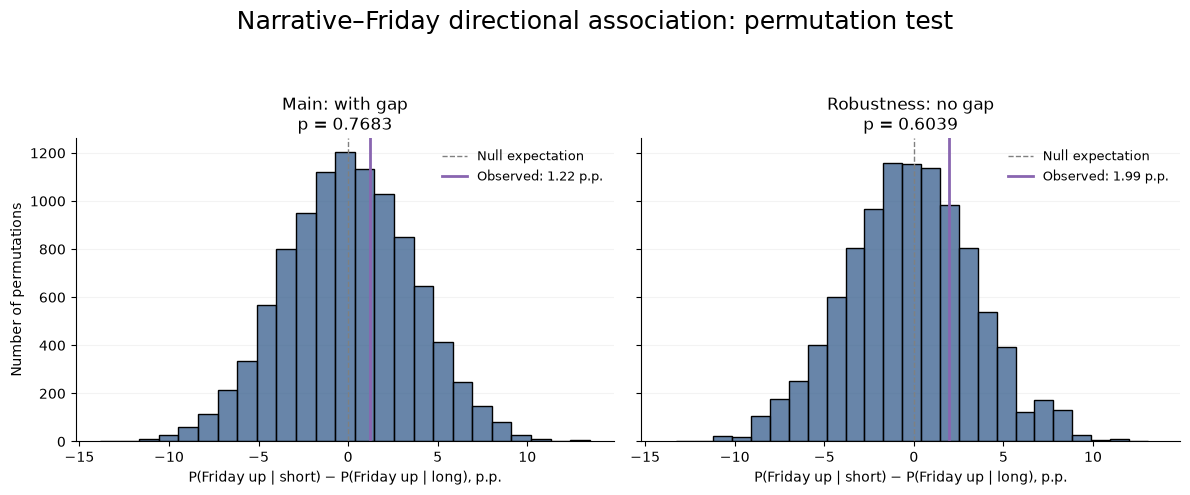

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

for ax, name in zip(axes, permutation_specifications.values()):
    row = permutation_results.loc[name]
    sns.histplot(permutation_distributions[name], bins=25,
                 color="#355C8C", alpha=0.75, ax=ax)
    ax.axvline(0, color="gray", linestyle="--", linewidth=1, label="Null expectation")
    ax.axvline(row["observed_difference_pp"], color="#8965B0", linewidth=2,
               label=f"Observed: {row['observed_difference_pp']:.2f} p.p.")
    ax.set_title(f"{name}\np = {row['p_value_two_sided']:.4f}", fontsize=12)
    ax.set_xlabel("P(Friday up | short) − P(Friday up | long), p.p.")
    ax.set_ylabel("Number of permutations")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.15)
    ax.legend(frameon=False, fontsize=9)
    sns.despine(ax=ax)

axes[1].set_ylabel("")
fig.suptitle("Narrative–Friday directional association: permutation test", fontsize=18)
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

## 5.3 Interpretation

Compare `p_value_two_sided` with 0.05. Failure to reject H0 means that this test
does not find evidence of directional association; it does not prove independence.

Section 4.4 compared reversal rates, where success meant Friday **up** after short
but Friday **down** after long. Here success means Friday **up in both groups**.
Consequently, a significant reversal-rate difference in 4.4 can coexist with a
non-significant directional-association test here.


In [25]:
for name, row in permutation_results.iterrows():
    if row["reject_H0_at_5pct"]:
        conclusion = "Evidence of directional association under the global-shuffle assumptions."
    else:
        conclusion = "No evidence of directional association under the global-shuffle assumptions."
    print(f"{name}: {conclusion} (p = {row['p_value_two_sided']:.4f})")

Main: with gap: No evidence of directional association under the global-shuffle assumptions. (p = 0.7683)
Robustness: no gap: No evidence of directional association under the global-shuffle assumptions. (p = 0.6039)


# 6. Overall Conclusions


This study asked whether Friday is more likely to reverse than continue the
direction of the preceding four-day move in GC gold futures. The main test
included the weekend gap, while the robustness check excluded it. A reversal
means that Friday's open-to-close move has the opposite sign to the prior move;
it does not require Friday to recover the entire earlier move. Neutral Fridays
were excluded from the directional percentages.

**There was no clear overall preference for reversal.** Reversals accounted for
50.28% of directional outcomes in the main test and 50.79% in the robustness
check, both close to an even split with continuation.

**The results differed when split by prior narrative.** After a bearish narrative,
Friday reversed upward in 55.79% of cases in the main test and 56.16% in the
robustness check. The corresponding exact 95% confidence intervals were
50.30–61.17% and 50.90–61.32%. One-sided binomial tests found evidence that these
conditional reversal probabilities exceeded 50% (p = 0.0191 and 0.0106).
These tests concerned Fridays after bearish narratives, not all Fridays.
The intervals reflect uncertainty in the estimates, rather than a forecast
that future reversal rates will reach their upper bounds.

After a bullish narrative, reversal meant a negative Friday and occurred in
45.43% and 45.82% of cases. Reversal was therefore about 10.35 percentage points
more frequent after bearish than bullish narratives. Fisher's exact tests found
this difference statistically significant (p = 0.0058 and 0.0047).

**That difference does not establish an additional narrative effect.** Fridays
were more often positive after both narrative directions: in the main sample,
55.79% after bearish narratives versus 54.57% after bullish narratives. A positive
Friday counts as reversal in the first group but continuation in the second.
Thus a general Friday upward tendency can explain an asymmetry in reversal
rates without requiring a relationship between narrative direction and Friday
direction. Across all available non-neutral Fridays, 54.81% were positive;
this full-sample figure is descriptive and was not the subject of the binomial
tests above.

The permutation test addressed this distinction by shuffling Friday moves
between weeks while preserving their observed distribution and upward bias.
The actual differences in positive-Friday rates between bearish and bullish
narratives were only 1.22 and 1.99 percentage points. They were not unusual
relative to random pairings (two-sided p = 0.7683 and 0.6039). We therefore
**did not find sufficient evidence that the direction of the preceding narrative
provided additional information about Friday's direction**. This is a failure
to find evidence of a relationship, not proof that no relationship exists.

The scatter plots likewise showed no obvious linear relationship between the
sizes of the four-day and Friday moves. However, nonlinear relationships or
effects restricted to unusually large moves were not formally tested.

These are exploratory findings for the sample and definitions used here.
The binomial and Fisher tests assume independent observations; the binomial
model also assumes a constant success probability. Global permutation assumes
exchangeable weeks and does not preserve changing regimes or serial dependence.
The two specifications have overlapping samples, so their agreement is a
sensitivity check rather than independent confirmation.

The practical takeaway is limited to the **observed general tendency for Fridays
to be positive**. The results do not justify treating a preceding bearish
narrative as a confirmed additional bullish signal. This project answers a
research question and does not establish a trading strategy or explain the
cause of the Friday upward tendency.